# Kernel PCA

PCA (`34_pca`) can only find **straight** directions, so it cannot untangle two concentric rings: both have the same mean and the same variance in every direction. Kernel PCA does PCA in a **curved, high-dimensional feature space** `φ(x)` — without ever computing `φ`, thanks to the kernel trick.

## How it works

1. Pick a kernel `k(a, b) = φ(a)·φ(b)` and build the `n × n` matrix `K`:
   - `linear`: `a·b` (gives ordinary PCA back)
   - `poly`: `(γ·a·b + c₀)^d`
   - `rbf`: `exp(−γ‖a − b‖²)`
2. **Center** it so the implicit features have zero mean: `Kc = K − 1K − K1 + 1K1`.
3. Eigendecompose `Kc`. The score of training point `i` on component `j` is `√λⱼ · vⱼ[i]`.
4. A **new** point is scored with its kernel row against the training set, centered the same way, times `vⱼ/√λⱼ`.

On two rings an RBF kernel makes points on the same ring similar, so the first component alone splits inner from outer — the demo shows a single threshold separating them (≥ 99%) where PCA gets ~50–70%.

Cost: stores and eigendecomposes the full `n × n` matrix (`O(n²)` memory, `O(n³)` time), so it suits thousands of points, not millions. `γ` matters a lot — too large and every point is only similar to itself.

## Usage

```python
# (the class is defined in the Implementation section below)

kpca = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit(X)
Z = kpca.transform(X)
Z_new = kpca.transform(X_new)   # unseen points
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class KernelPCA:
    """PCA in an implicit high-dimensional feature space, via the kernel trick.

    Plain PCA only finds straight directions. Kernel PCA maps points through phi(x) (never computed)
    and does PCA there, needing only the kernel k(a, b) = phi(a) . phi(b):

    1. Kernel matrix K (n x n); center it so the implicit features have zero mean.
    2. Eigendecompose it. A component's score for training point i is sqrt(lambda) * v[i].
    3. A new point is scored with its (identically centered) kernel row against the training set,
       scaled by 1/sqrt(lambda).

    Kernels: "linear" (== ordinary PCA), "poly" (gamma*a.b + coef0)^degree, "rbf" exp(-gamma*|a-b|^2).

    ponytail: stores the full n x n kernel matrix and eigendecomposes it, O(n^2) memory / O(n^3) time."""

    def __init__(self, n_components=2, kernel="rbf", gamma=None, degree=3, coef0=1.0):
        self.n_components = n_components
        self.kernel = kernel
        self.gamma = gamma  # None -> 1 / n_features
        self.degree = degree
        self.coef0 = coef0

    def _kernel(self, A, B):
        if self.kernel == "linear":
            return A @ B.T
        if self.kernel == "poly":
            return (self.gamma_ * (A @ B.T) + self.coef0) ** self.degree
        if self.kernel == "rbf":
            d2 = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
            return np.exp(-self.gamma_ * np.maximum(d2, 0.0))
        raise ValueError(f"unknown kernel: {self.kernel}")

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.gamma_ = self.gamma if self.gamma is not None else 1.0 / X.shape[1]
        K = self._kernel(X, X)
        self.K_col_mean_ = K.mean(axis=0)
        self.K_mean_ = K.mean()
        Kc = K - self.K_col_mean_[None, :] - self.K_col_mean_[:, None] + self.K_mean_

        eigenvalues, eigenvectors = np.linalg.eigh(Kc)
        order = np.argsort(eigenvalues)[::-1][: self.n_components]
        self.eigenvalues_ = eigenvalues[order]
        keep = self.eigenvalues_ > 1e-10  # drop numerically-zero components
        self.eigenvalues_ = self.eigenvalues_[keep]
        self.alphas_ = eigenvectors[:, order][:, keep] / np.sqrt(self.eigenvalues_)
        self.X_fit_ = X
        return self

    def transform(self, X):
        K = self._kernel(np.asarray(X, dtype=float), self.X_fit_)
        Kc = K - K.mean(axis=1, keepdims=True) - self.K_col_mean_[None, :] + self.K_mean_
        return Kc @ self.alphas_

    def fit_transform(self, X):
        return self.fit(X).transform(X)

## See it work

### 1. Linear PCA cannot unroll concentric circles; kernel PCA can

PCA only finds straight directions, so projecting two concentric rings onto any line leaves the classes mixed. Kernel PCA with an RBF kernel finds directions in an implicit feature space in which the rings **separate along the first component**.

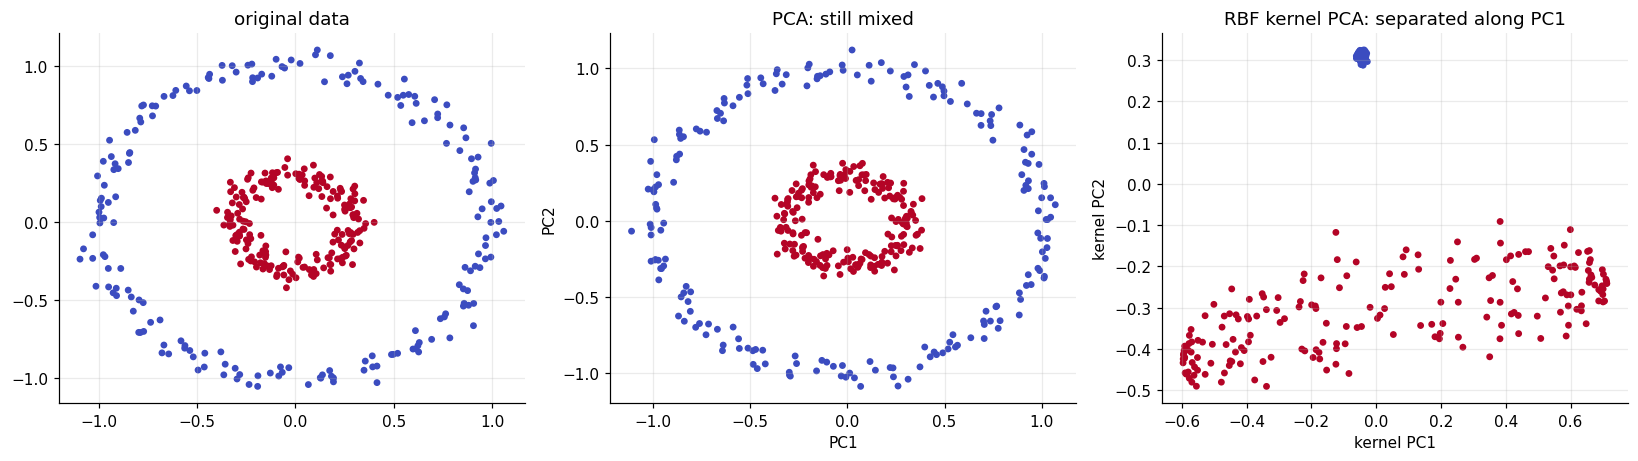

In [3]:
from sklearn.datasets import make_circles
from sklearn.decomposition import PCA as SkPCA

X, y = make_circles(n_samples=400, factor=0.3, noise=0.05, random_state=0)
Z_lin = SkPCA(2).fit_transform(X); Z_rbf = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit_transform(X)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
axes[0].scatter(*X.T, c=y, cmap="coolwarm", s=12); axes[0].set_title("original data")
axes[1].scatter(*Z_lin.T, c=y, cmap="coolwarm", s=12); axes[1].set(title="PCA: still mixed", xlabel="PC1", ylabel="PC2")
axes[2].scatter(*Z_rbf.T, c=y, cmap="coolwarm", s=12); axes[2].set(title="RBF kernel PCA: separated along PC1", xlabel="kernel PC1", ylabel="kernel PC2")
plt.tight_layout(); plt.show()

### 2. `gamma` sets how local the similarity is

`gamma` is the inverse width of the RBF similarity. Tiny `gamma`: everything is "similar", the embedding is close to linear PCA. Moderate: the structure unrolls. Huge: each point is only similar to itself and the embedding degenerates into noise.

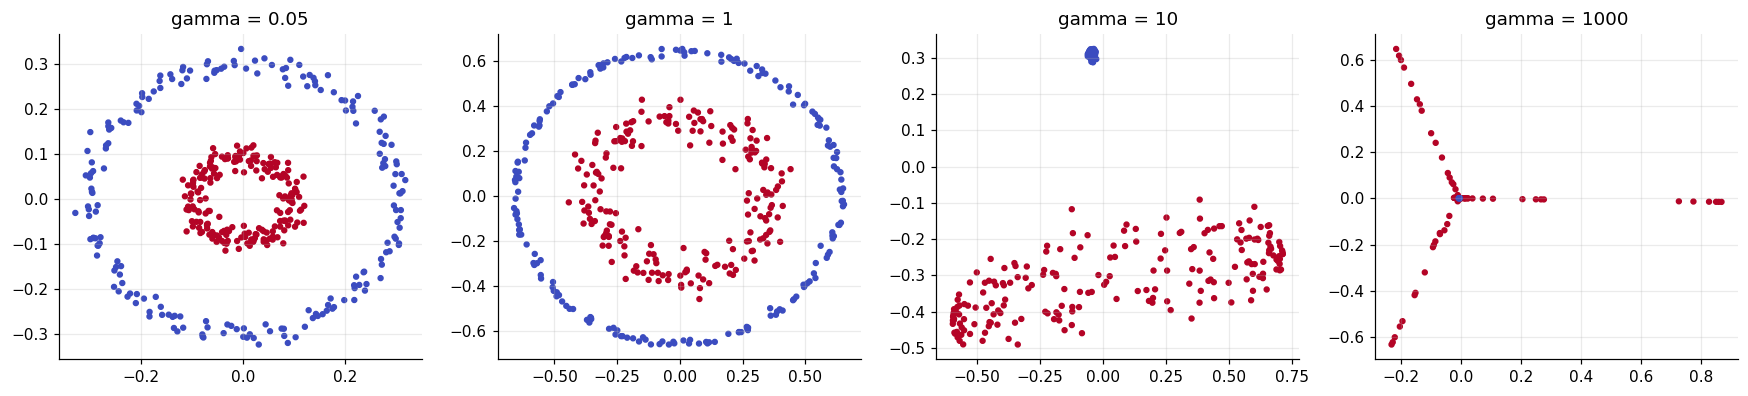

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
for ax, g in zip(axes, [0.05, 1.0, 10.0, 1000.0]):
    Z = KernelPCA(n_components=2, kernel="rbf", gamma=g).fit_transform(X)
    ax.scatter(*Z.T, c=y, cmap="coolwarm", s=10); ax.set_title(f"gamma = {g:g}")
plt.tight_layout(); plt.show()

### 3. Out-of-sample: `transform` works on new points

Because the model keeps the training points and the centring statistics, new points can be projected consistently, which t-SNE cannot do.

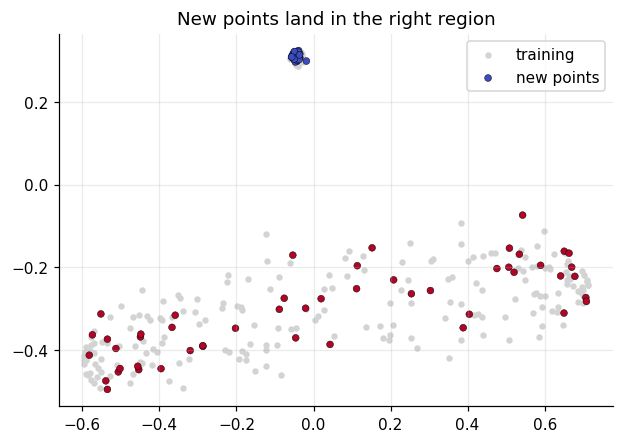

In [5]:
kp = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit(X)
X_new, y_new = make_circles(n_samples=100, factor=0.3, noise=0.05, random_state=7)
Zt = kp.transform(X)
plt.figure(figsize=(6.5, 4.4)); plt.scatter(*Zt.T, c="lightgray", s=10, label="training")
plt.scatter(*kp.transform(X_new).T, c=y_new, cmap="coolwarm", s=20, edgecolor="k", linewidth=0.3, label="new points"); plt.legend(); plt.title("New points land in the right region"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from sklearn.datasets import make_circles
from sklearn.decomposition import KernelPCA as SklearnKPCA, PCA

X, y = make_circles(n_samples=300, factor=0.3, noise=0.05, random_state=0)
X_new, _ = make_circles(n_samples=50, factor=0.3, noise=0.05, random_state=7)

for name, params in {"rbf": dict(kernel="rbf", gamma=10), "poly": dict(kernel="poly", gamma=1.0, degree=2), "linear": dict(kernel="linear")}.items():
    ours = KernelPCA(n_components=2, **params).fit(X)
    theirs = SklearnKPCA(n_components=2, **params).fit(X)
    # eigenvector sign is arbitrary, so compare magnitudes
    assert np.allclose(np.abs(ours.transform(X)), np.abs(theirs.transform(X)), atol=1e-6), name
    assert np.allclose(np.abs(ours.transform(X_new)), np.abs(theirs.transform(X_new)), atol=1e-6), name
    print("%-6s matches sklearn (training points and unseen points)" % name)


def best_threshold_accuracy(z):  # best single-threshold split of the two rings, either orientation
    acc = np.array([((z > t) == y).mean() for t in z])
    return np.maximum(acc, 1 - acc).max()


best = lambda Z: max(best_threshold_accuracy(Z[:, j]) for j in range(2))
rbf = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit_transform(X)
pca = PCA(n_components=2).fit_transform(X)
print("best 1-D threshold accuracy on the rings: kernel PCA=%.2f  PCA=%.2f" % (best(rbf), best(pca)))
assert best(rbf) > 0.99 and best(pca) < 0.8

rbf    matches sklearn (training points and unseen points)
poly   matches sklearn (training points and unseen points)
linear matches sklearn (training points and unseen points)
best 1-D threshold accuracy on the rings: kernel PCA=1.00  PCA=0.70


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_training_scores_are_sqrt_eigenvalue_times_eigenvector():
    # transform() on the training set must agree with the textbook scores sqrt(lambda) * v
    X = np.random.default_rng(0).normal(size=(40, 3))
    model = KernelPCA(n_components=3, kernel="rbf", gamma=0.5).fit(X)
    scores = model.transform(X)
    assert np.allclose((scores ** 2).sum(axis=0), model.eigenvalues_)  # ||score||^2 = lambda
    assert np.allclose(scores.mean(axis=0), 0.0, atol=1e-10)             # centered in feature space


def test_linear_kernel_equals_pca():
    X = np.random.default_rng(1).normal(size=(60, 4)) * [5, 3, 1, 0.5]
    Z = KernelPCA(n_components=2, kernel="linear").fit_transform(X)
    Xc = X - X.mean(axis=0)
    _, vecs = np.linalg.eigh(np.cov(Xc, rowvar=False))
    pca = Xc @ vecs[:, ::-1][:, :2]
    assert np.allclose(np.abs(Z), np.abs(pca), atol=1e-8)


def test_rbf_unrolls_concentric_circles_where_pca_cannot():
    from sklearn.datasets import make_circles

    X, y = make_circles(n_samples=200, factor=0.3, noise=0.04, random_state=0)

    def separable(z):  # can one threshold on this axis split the two rings?
        a, b = z[y == 0], z[y == 1]
        return a.max() < b.min() or b.max() < a.min()

    kpca = KernelPCA(n_components=2, kernel="rbf", gamma=10).fit_transform(X)
    assert any(separable(kpca[:, j]) for j in range(2))
    linear = KernelPCA(n_components=2, kernel="linear").fit_transform(X)
    assert not any(separable(linear[:, j]) for j in range(2))


def test_transform_new_points_matches_training_rows():
    X = np.random.default_rng(2).normal(size=(30, 2))
    model = KernelPCA(n_components=2, kernel="poly", gamma=1.0, degree=2).fit(X)
    assert model.transform(X[:5]).shape == (5, 2)
    assert np.allclose(model.transform(X[:5]), model.fit_transform(X)[:5])

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_training_scores_are_sqrt_eigenvalue_times_eigenvector
PASS test_linear_kernel_equals_pca
PASS test_rbf_unrolls_concentric_circles_where_pca_cannot
PASS test_transform_new_points_matches_training_rows

all 4 tests passed


## Takeaways

- **Use it** for non-linear dimensionality reduction when you also need to project new data, and as feature extraction before a linear classifier.
- **How:** build the kernel matrix, **centre it in feature space** (`K − 1K − K1 + 1K1`), eigendecompose, scale eigenvectors by `1/√λ`; project a new point with its (identically centred) kernel row.
- **Pitfalls:** `O(n²)` memory and `O(n³)` time; `gamma` needs tuning; no inverse map from the embedding back to the input space.
- **Interview line:** *"PCA on the centred kernel matrix: the kernel trick gives non-linear components without ever building the feature map."*